# Baseline results

Errors of the two reference forecasts of the README on the validation
and test periods: the seasonal naive forecast (7 days, and the 364-day
variant) and the RTE day-ahead forecast.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from load_forecast.evaluation.backtest import build_forecasts, summarize
from load_forecast.evaluation.baselines import rte_day_ahead, seasonal_naive
from load_forecast.evaluation.data import load_actuals
from load_forecast.evaluation.protocol import TEST, VALIDATION, target_days

plt.rcParams["figure.dpi"] = 80

In [2]:
actuals = load_actuals()
consumption = actuals["consumption_mw"]


def naive_7(slots):
    return seasonal_naive(consumption, slots, days=7)


def naive_364(slots):
    return seasonal_naive(consumption, slots, days=364)


def rte(slots):
    return rte_day_ahead(actuals["forecast_d1_mw"], slots)


methods = {"Naive 7 days": naive_7, "Naive 364 days": naive_364, "RTE day-ahead": rte}

In [3]:
periods = {"validation": target_days(*VALIDATION), "test": target_days(*TEST)}

results = {}
for period_name, days in periods.items():
    for method_name, method in methods.items():
        results[(period_name, method_name)] = build_forecasts(method, consumption, days)

len(results)

6

In [4]:
rows = []
for (period_name, method_name), forecasts in results.items():
    scores = summarize(forecasts)
    scores["period"] = period_name
    scores["method"] = method_name
    rows.append(scores)

overall = pd.concat(rows).set_index(["period", "method"])
overall.round(2)

mae_mw  mape_pct
period     method                           
validation Naive 7 days    3378.53      6.35
           Naive 364 days  3615.14      6.68
           RTE day-ahead   1309.20      2.63
test       Naive 7 days    3445.45      6.42
           Naive 364 days  3414.00      6.29
           RTE day-ahead   1387.69      2.74

## Overall errors

On the validation period, the RTE day-ahead forecast has a MAPE of
about 2.63%, the 7-day naive forecast about 6.35% and the 364-day naive
forecast about 6.68 %.

Although the results are substantially the same, we keep the 7-day naive forecast
as the reference to beat. The gap between it and RTE is
about 3.7%: this is the room the model can gain from
weather and calendar information.

Errors on the test period are close to those from those on the
validation period, so the measures are stable from one
year to the next.

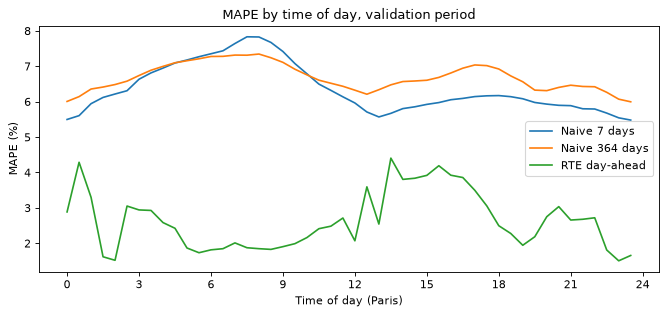

In [5]:
for forecasts in results.values():
    paris = forecasts.index.tz_convert("Europe/Paris")
    forecasts["time_of_day"] = paris.hour + paris.minute / 60

fig, ax = plt.subplots(figsize=(10, 4))
for method_name in methods:
    by_time = summarize(results[("validation", method_name)], by="time_of_day")
    ax.plot(by_time.index, by_time["mape_pct"], label=method_name)
ax.set_xlabel("Time of day (Paris)")
ax.set_ylabel("MAPE (%)")
ax.set_xticks(range(0, 25, 3))
ax.set_title("MAPE by time of day, validation period")
ax.legend()
plt.show()

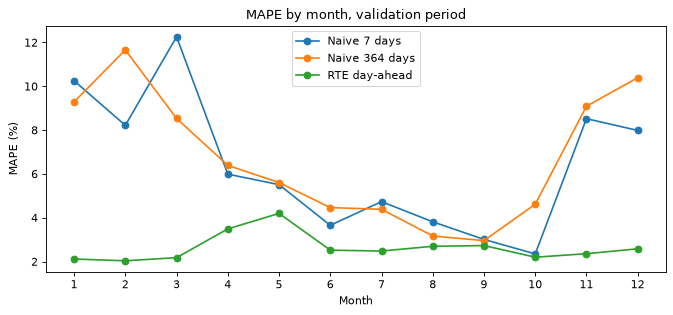

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
for method_name in methods:
    by_month = summarize(results[("validation", method_name)], by="month")
    ax.plot(by_month.index, by_month["mape_pct"], marker="o", label=method_name)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("MAPE (%)")
ax.set_title("MAPE by month, validation period")
ax.legend()
plt.show()

## Errors by time of day and by month

By time of day: the RTE forecast is most accurate at night and least
accurate in the afternoon, with a MAPE of up to about 4 %, compared with
2.6 % on average. Night-time consumption is stable and easy to predict;
afternoon consumption is harder.

By month: the naive forecasts are least accurate in winter, likely
because temperature changes from one week to the next have a strong
effect on consumption when heating is on. The RTE forecast is least
accurate around May, possibly because of the many public holidays and
bridge days in that month.